# Notebook Piloto — Benchmark de Conteo (Parte 1: Evaluación)

**Modelo:** InternVL2-1B — mismo modelo usado en el piloto de TallyQA, para que los resultados sean comparables.
**Benchmark:** CAPTURe — subconjuntos **real** (824 imágenes, objetos cotidianos densos, conteo 8-907) y **sintético** (1150 imágenes, formas generadas, conteo 5-15 con oclusión controlada vía `num_occluded`).

**Fuente:** [atinp/CAPTURe](https://huggingface.co/datasets/atinp/CAPTURe) en HuggingFace Hub.

**Diferencias clave respecto al notebook de TallyQA:**
- No hay pregunta en texto — se construye a partir de `object` (real) o `color`+`dot_shape` (sintético).
- Las imágenes son archivos locales tras descomprimir el zip (no hay que descargarlas una por una vía HTTP) — el paso de imágenes es mucho más rápido.
- `real` y `sintético` se corren juntos en el mismo loop, pero se reportan por separado porque tienen rangos de conteo completamente distintos.
- `real` tiene un rango de conteo enorme (8-907) — el desglose usa **buckets por cuartil** en vez de valor exacto (a diferencia de TallyQA, donde el rango 0-15 permitía desglosar valor por valor). `sintético` sí se desglosa por valor exacto, igual que TallyQA, más un desglose adicional por `num_occluded` (la variable de oclusión controlada).
- **Importante:** `log_prob` y `density_map_sum` en los metadatos de `real` NO son predicciones de ningún modelo — son metadata de cómo CAPTURe generó el ground truth (vía mapas de densidad). No se usan acá.

**Requisitos de entorno:** GPU activada en Colab (T4 gratuita alcanza).

**Alcance:** solo Parte 1 (evaluación/métricas). La Parte 2 (explicabilidad/grounding, usando el `bbox` de referencia en `real`) va en un notebook separado.


## 1. Instalación de dependencias

In [1]:
# IMPORTANTE: se fija transformers==4.46.2 (última release de la serie 4.x).
# transformers>=5.0 tiene un bug de compatibilidad conocido con modelos que usan
# trust_remote_code (Moondream2, Molmo, y varios otros) al inicializar el tie de pesos:
# https://github.com/huggingface/transformers/issues/43883
!pip install -q "transformers==4.46.2" accelerate einops timm pillow psutil huggingface_hub sentencepiece
print("Dependencias instaladas.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 81.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 30.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 76.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Dependencias instaladas.


In [2]:
import transformers
print(f"Versión de transformers activa: {transformers.__version__}")

if not transformers.__version__.startswith("4."):
    raise RuntimeError(
        "transformers quedó en una version >= 5.x a pesar del pip install de la celda anterior.\n"
        "Esto pasa cuando Colab ya tenia una version distinta cargada en memoria ANTES de correr "
        "esta celda (el pip install no afecta un modulo que Python ya importo en esta sesion).\n\n"
        "SOLUCION: Entorno de ejecucion > Reiniciar sesion, y luego "
        "Entorno de ejecucion > Ejecutar todo, para que la version fijada (4.46.2) quede activa "
        "desde el principio de una sesion limpia."
    )
print("Version compatible con el codigo de Moondream2 (trust_remote_code). Continuando...")


Versión de transformers activa: 4.46.2
Version compatible con el codigo de Moondream2 (trust_remote_code). Continuando...


## 2. Configuración de la corrida

`SAMPLE_SIZE_REAL` / `SAMPLE_SIZE_SINTETICO` en `None` usan el dataset **completo** (824 / 1150 — ambos son
chicos, no hace falta muestrear para el análisis final). Se dejan en 50/50 por defecto acá solo para que
la primera corrida de validación sea rápida; súbelos una vez confirmado que todo corre bien.


In [3]:
MODEL_ID = "OpenGVLab/InternVL2-1B"
MODEL_REVISION = "main"

BENCHMARK_NAME = "CAPTURe"

SAMPLE_SIZE_REAL = 100        # None o -1 = usar las 824 completas
SAMPLE_SIZE_SINTETICO = 100   # None o -1 = usar las 1150 completas
RANDOM_SEED = 42

TIMEOUT_SEGUNDOS = 30
PROMPT_SUFFIX = ""

OUTPUT_TXT_PATH = f"/content/resultados_{BENCHMARK_NAME}_{MODEL_ID.split('/')[-1]}.txt"
OUTPUT_CSV_PATH = f"/content/detalle_{BENCHMARK_NAME}_{MODEL_ID.split('/')[-1]}.csv"

print(f"Modelo:      {MODEL_ID} (revision={MODEL_REVISION})")
print(f"Benchmark:   {BENCHMARK_NAME} (real + sintético)")
print(f"Muestra:     real={SAMPLE_SIZE_REAL or 'completa'} | sintético={SAMPLE_SIZE_SINTETICO or 'completa'}")
print(f"Salida .txt: {OUTPUT_TXT_PATH}")


Modelo:      OpenGVLab/InternVL2-1B (revision=main)
Benchmark:   CAPTURe (real + sintético)
Muestra:     real=100 | sintético=100
Salida .txt: /content/resultados_CAPTURe_InternVL2-1B.txt


## 3. Cargar el modelo

In [4]:
import torch
from transformers import AutoTokenizer, AutoModel
import torchvision.transforms as T
from torchvision.transforms.functional import InterpolationMode

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo detectado: {device}")
if device == "cpu":
    print("ADVERTENCIA: sin GPU. La inferencia será muy lenta.")

if device == "cuda":
    torch.cuda.reset_peak_memory_stats()

# ── Preprocesamiento de imagen (específico de InternVL2) ──────────────────
# InternVL2 no usa AutoProcessor estándar — necesita su propio pipeline
# de normalización y división dinámica de la imagen en tiles.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

def _build_transform(input_size=448):
    return T.Compose([
        T.Lambda(lambda img: img.convert("RGB") if img.mode != "RGB" else img),
        T.Resize((input_size, input_size), interpolation=InterpolationMode.BICUBIC),
        T.ToTensor(),
        T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

def _dynamic_preprocess(image, image_size=448, min_num=1, max_num=6, use_thumbnail=True):
    """Divide la imagen en tiles según su aspecto para que el modelo vea más detalle."""
    w, h = image.size
    ratio = w / h
    ratios = {(i, j) for n in range(min_num, max_num + 1)
              for i in range(1, n + 1) for j in range(1, n + 1)
              if min_num <= i * j <= max_num}
    best = min(ratios, key=lambda r: abs(r[0] / r[1] - ratio))
    tw, th = image_size * best[0], image_size * best[1]
    img_resized = image.resize((tw, th))
    tiles = []
    for idx in range(best[0] * best[1]):
        col, row = idx % best[0], idx // best[0]
        box = (col * image_size, row * image_size,
               (col + 1) * image_size, (row + 1) * image_size)
        tiles.append(img_resized.crop(box))
    if use_thumbnail and len(tiles) > 1:
        tiles.append(image.resize((image_size, image_size)))
    return tiles

def preparar_imagen_internvl(imagen_pil, input_size=448, max_num=6):
    """Convierte PIL.Image a tensor listo para InternVL2."""
    transform = _build_transform(input_size)
    tiles = _dynamic_preprocess(imagen_pil, image_size=input_size,
                                 use_thumbnail=True, max_num=max_num)
    pixel_values = torch.stack([transform(t) for t in tiles])
    return pixel_values
# ─────────────────────────────────────────────────────────────────────────

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, trust_remote_code=True
)

model = AutoModel.from_pretrained(
    MODEL_ID,
    revision=MODEL_REVISION,
    torch_dtype=torch.bfloat16,
    low_cpu_mem_usage=True,
    trust_remote_code=True,
).eval()

if device == "cuda":
    model = model.cuda()

vram_after_load_mb = (torch.cuda.max_memory_allocated() / 1024**2) if device == "cuda" else 0
print(f"Modelo cargado. VRAM tras la carga: {vram_after_load_mb:.1f} MB")
# Silencia el warning repetitivo de pad_token_id en cada llamada a generate()
if model.generation_config.pad_token_id is None:
    model.generation_config.pad_token_id = model.generation_config.eos_token_id


# ── Interfaz común ──────────────────────────────────────────────
GENERATION_CONFIG = dict(max_new_tokens=64, do_sample=False)

def predecir(imagen, pregunta):
    """Recibe PIL.Image y str, devuelve str (respuesta cruda del modelo)."""
    pixel_values = preparar_imagen_internvl(imagen).to(torch.bfloat16).to(device)
    return model.chat(tokenizer, pixel_values, pregunta,
                      GENERATION_CONFIG, history=None, return_history=False)
# ────────────────────────────────────────────────────────────────

print("Interfaz predecir() lista.")


Dispositivo detectado: cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/265 [00:00<?, ?B/s]

... (8 outputs left out)

FlashAttention2 is not installed.


model.safetensors:   0%|          | 0.00/1.88G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/117 [00:00<?, ?B/s]

Modelo cargado. VRAM tras la carga: 1800.1 MB
Interfaz predecir() lista.


### Diagnóstico rápido de GPU

Si `Dispositivo del modelo` da `cpu`, esa es la causa de latencias de minutos por pregunta en vez de
segundos (ver la discusión del piloto de TallyQA) — reiniciar sesión y confirmar GPU antes de seguir.


In [5]:
print("torch.cuda.is_available():", torch.cuda.is_available())
print("Dispositivo del modelo:", next(model.parameters()).device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
!nvidia-smi --query-gpu=name,memory.used,memory.total,utilization.gpu --format=csv 2>/dev/null || echo "nvidia-smi no disponible (sin GPU asignada)"


torch.cuda.is_available(): True
Dispositivo del modelo: cuda:0
GPU: Tesla T4
name, memory.used [MiB], memory.total [MiB], utilization.gpu [%]
Tesla T4, 1977 MiB, 15360 MiB, 23 %


## 4. Descargar CAPTURe (real + sintético) desde HuggingFace

A diferencia de TallyQA, las imágenes vienen empaquetadas en zips (no hay que pedirlas una por una a un
servidor externo) — esto hace que el paso de "cargar imagen" en el loop de inferencia sea prácticamente
instantáneo comparado con TallyQA.


In [6]:
import os, zipfile
from huggingface_hub import hf_hub_download
import pandas as pd

print("Descargando real_dataset.zip...")
real_zip = hf_hub_download(repo_id="atinp/CAPTURe", filename="real_dataset.zip", repo_type="dataset")
print("Descargando synthetic_dataset.zip...")
syn_zip = hf_hub_download(repo_id="atinp/CAPTURe", filename="synthetic_dataset.zip", repo_type="dataset")
print("Descargando real_metadata.json...")
real_meta = hf_hub_download(repo_id="atinp/CAPTURe", filename="real_metadata.json", repo_type="dataset")
print("Descargando synthetic_metadata.json...")
syn_meta = hf_hub_download(repo_id="atinp/CAPTURe", filename="synthetic_metadata.json", repo_type="dataset")

REAL_IMAGE_DIR = "/content/real_dataset/"
SYNTHETIC_IMAGE_DIR = "/content/synthetic_dataset/"

with zipfile.ZipFile(real_zip, "r") as z:
    z.extractall()
if os.path.exists("dataset") and not os.path.exists("real_dataset"):
    os.rename("dataset", "real_dataset")

with zipfile.ZipFile(syn_zip, "r") as z:
    z.extractall()
if os.path.exists("dataset") and not os.path.exists("synthetic_dataset"):
    os.rename("dataset", "synthetic_dataset")

real_metadata_df = pd.read_json(real_meta)
synthetic_metadata_df = pd.read_json(syn_meta)

print(f"\nreal_metadata_df: {len(real_metadata_df)} filas | rango ground_truth: "
      f"{real_metadata_df['ground_truth'].min()}-{real_metadata_df['ground_truth'].max()}")
print(f"synthetic_metadata_df: {len(synthetic_metadata_df)} filas | rango ground_truth: "
      f"{synthetic_metadata_df['ground_truth'].min()}-{synthetic_metadata_df['ground_truth'].max()}")
print("\nDatasets y metadatos descargados y extraídos correctamente.")


Descargando real_dataset.zip...


real_dataset.zip:   0%|          | 0.00/46.5M [00:00<?, ?B/s]

Descargando synthetic_dataset.zip...


synthetic_dataset.zip:   0%|          | 0.00/784k [00:00<?, ?B/s]

Descargando real_metadata.json...


real_metadata.json: 0.00B [00:00, ?B/s]

Descargando synthetic_metadata.json...


synthetic_metadata.json: 0.00B [00:00, ?B/s]


real_metadata_df: 824 filas | rango ground_truth: 8-907
synthetic_metadata_df: 1150 filas | rango ground_truth: 5-15

Datasets y metadatos descargados y extraídos correctamente.


In [ ]:
# --- INSPECCION TEMPORAL: solo para confirmar si real_metadata trae info de oclusion ---
# No modifica nada del pipeline, solo imprime columnas y ejemplos.
print("Columnas de real_metadata_df:")
print(real_metadata_df.columns.tolist())
print()
print(real_metadata_df.head(3).to_string())
print()
print("Columnas de synthetic_metadata_df (para comparar):")
print(synthetic_metadata_df.columns.tolist())


## 5. Construcción de preguntas y muestreo

`real` no trae pregunta en texto — se arma como *"How many {object} are there?"*.
`sintético` se arma como *"How many {color} {dot_shape}s are there?"* (lo que se cuenta son los puntos/formas
chicas, no la forma grande de fondo que genera la oclusión).

*Nota: algunos nombres de `object` pueden sonar gramaticalmente raros en la pregunta (ej. "cupcake tray"
en singular) — no es un bug del pipeline, es el nombre de categoría tal cual viene en el dataset.*

Muestreo aleatorio simple (no estratificado) sobre cada subconjunto. **Aviso:** dado que `ground_truth` en
`real` está con cola muy larga (media 60, mediana 28.5, máx 907), una muestra chica va a tener pocos casos
de conteo muy alto — mismo fenómeno que vimos en TallyQA. Si esto importa, se puede agregar muestreo
estratificado por magnitud igual que se hizo allá.


In [7]:
import random

random.seed(RANDOM_SEED)

def construir_item_real(row):
    return {
        "subset": "real",
        "image_path": os.path.join(REAL_IMAGE_DIR, row["image_file"]),
        "pregunta": f"Count the exact number of {row['object']} in the image. "
                    f"Assume the pattern of {row['object']} continues behind any black box. "
                    f"Provide the total number of {row['object']} as if the black box were not there.",

        "ground_truth": int(row["ground_truth"]),
        "categoria": row["object"],
        "num_occluded": None,
        "image_file": row["image_file"],
    }

def construir_item_sintetico(row):
    return {
        "subset": "sintetico",
        "image_path": os.path.join(SYNTHETIC_IMAGE_DIR, row["image_file"]),
        "pregunta": f"Your task is to count objects in the image. "
                    f"Assume the pattern of {row['color']} {row['dot_shape']}s continues behind the black box. "
                    f"First, state what the pattern is, then give your final count.",
        "ground_truth": int(row["ground_truth"]),
        "categoria": f"{row['color']}_{row['dot_shape']}",
        "num_occluded": int(row["num_occluded"]),
        "image_file": row["image_file"],
    }

n_real = len(real_metadata_df) if not SAMPLE_SIZE_REAL or SAMPLE_SIZE_REAL < 0 else min(SAMPLE_SIZE_REAL, len(real_metadata_df))
n_sint = len(synthetic_metadata_df) if not SAMPLE_SIZE_SINTETICO or SAMPLE_SIZE_SINTETICO < 0 else min(SAMPLE_SIZE_SINTETICO, len(synthetic_metadata_df))

filas_real = real_metadata_df.sample(n=n_real, random_state=RANDOM_SEED).to_dict("records")
filas_sint = synthetic_metadata_df.sample(n=n_sint, random_state=RANDOM_SEED).to_dict("records")

muestra = [construir_item_real(r) for r in filas_real] + [construir_item_sintetico(r) for r in filas_sint]
random.shuffle(muestra)

print(f"Muestra REAL:      {n_real}/{len(real_metadata_df)}")
print(f"Muestra SINTÉTICA: {n_sint}/{len(synthetic_metadata_df)}")
print(f"Total combinado:   {len(muestra)}")
print(f"\nEjemplo real:      {[m for m in muestra if m['subset']=='real'][0]}")
print(f"Ejemplo sintético: {[m for m in muestra if m['subset']=='sintetico'][0]}")


Muestra REAL:      100/824
Muestra SINTÉTICA: 100/1150
Total combinado:   200

Ejemplo real:      {'subset': 'real', 'image_path': '/content/real_dataset/7629.jpg', 'pregunta': 'Count the exact number of oranges in the image. Assume the pattern of oranges continues behind any black box. Provide the total number of oranges as if the black box were not there.', 'ground_truth': 437, 'categoria': 'oranges', 'num_occluded': None, 'image_file': '7629.jpg'}
Ejemplo sintético: {'subset': 'sintetico', 'image_path': '/content/synthetic_dataset/circle_8_dots_4_green_dots.png', 'pregunta': 'Your task is to count objects in the image. Assume the pattern of green circles continues behind the black box. First, state what the pattern is, then give your final count.', 'ground_truth': 8, 'categoria': 'green_circle', 'num_occluded': 1, 'image_file': 'circle_8_dots_4_green_dots.png'}


## 6. Prueba visual rápida

Confirmar que las imágenes cargan bien antes de lanzar el loop completo.


[real] Count the exact number of oranges in the image. Assume the pattern of oranges continues behind any black box. Provide the total number of oranges as if the black box were not there.  (ground truth: 437)


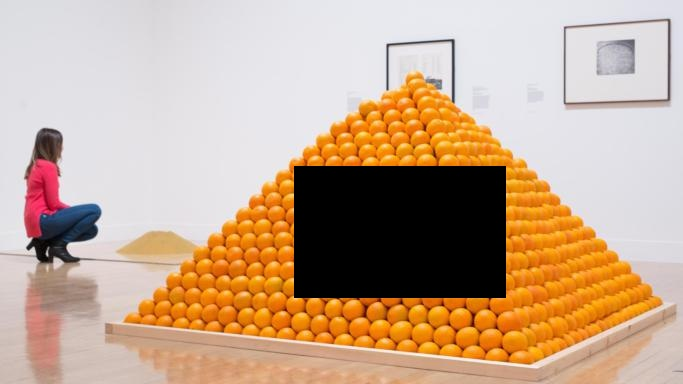

[sintetico] Your task is to count objects in the image. Assume the pattern of green circles continues behind the black box. First, state what the pattern is, then give your final count.  (ground truth: 8)


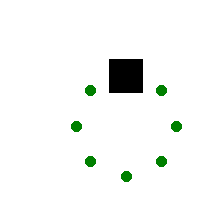

In [8]:
from PIL import Image
from IPython.display import display

item_real_prueba = next(m for m in muestra if m["subset"] == "real")
item_sint_prueba = next(m for m in muestra if m["subset"] == "sintetico")

for item in [item_real_prueba, item_sint_prueba]:
    img = Image.open(item["image_path"]).convert("RGB")
    print(f"[{item['subset']}] {item['pregunta']}  (ground truth: {item['ground_truth']})")
    display(img)


## 7. Loop de inferencia

Misma lógica de timeout + parseo con fallback de números en palabras que en TallyQA. La carga de imagen
es local (sin red), así que el tiempo por pregunta debería reflejar casi puramente la latencia del modelo.


In [9]:
import re, time, concurrent.futures

NUMEROS_EN_PALABRAS = {
    "zero": 0, "none": 0, "no": 0, "one": 1, "two": 2, "three": 3, "four": 4,
    "five": 5, "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10,
    "eleven": 11, "twelve": 12, "thirteen": 13, "fourteen": 14, "fifteen": 15,
    "sixteen": 16, "seventeen": 17, "eighteen": 18, "nineteen": 19, "twenty": 20,
}

def extraer_entero(texto):
    """Extrae el conteo de la respuesta en texto libre del modelo.
    Primero busca un digito; si no hay, busca un numero escrito en palabras.
    Devuelve None solo si de verdad no se encuentra nada interpretable (parse fail real)."""
    match = re.search(r"-?\d+", texto)
    if match:
        return int(match.group())
    texto_limpio = re.sub(r"[^\w\s]", " ", texto.lower())
    for palabra, valor in NUMEROS_EN_PALABRAS.items():
        if re.search(rf"\b{palabra}\b", texto_limpio):
            return valor
    return None


def query_con_timeout(imagen, pregunta, timeout_seg):
    """Corre model.query en un hilo aparte con limite de tiempo (ver notebook de TallyQA para el detalle
    de la limitacion conocida: el hilo sigue en segundo plano si se cumple el timeout)."""
    executor = concurrent.futures.ThreadPoolExecutor(max_workers=1)
    future = executor.submit(predecir, imagen, pregunta)  # ← usando la interfaz
    try:
        resultado = future.result(timeout=timeout_seg)
        executor.shutdown(wait=False)
        return resultado, False
    except concurrent.futures.TimeoutError:
        executor.shutdown(wait=False)
        return None, True


resultados = []
fallos_carga = 0
n_timeouts = 0

print(f"Iniciando inferencia sobre {len(muestra)} preguntas (timeout={TIMEOUT_SEGUNDOS}s)...\n")

for i, item in enumerate(muestra):
    try:
        img = Image.open(item["image_path"]).convert("RGB")
    except Exception as e:
        fallos_carga += 1
        print(f"[{i+1}/{len(muestra)}] Error abriendo imagen ({item['image_path']}): {e}")
        continue

    pregunta_modelo = item["pregunta"]

    t0 = time.time()
    respuesta_cruda, timed_out = query_con_timeout(img, pregunta_modelo, TIMEOUT_SEGUNDOS)
    t1 = time.time()

    if timed_out:
        n_timeouts += 1
        pred = None
        parse_fail = False
    else:
        pred = extraer_entero(respuesta_cruda)
        parse_fail = pred is None

    resultados.append({
        "subset": item["subset"],
        "image_file": item["image_file"],
        "pregunta": item["pregunta"],
        "categoria": item["categoria"],
        "num_occluded": item["num_occluded"],
        "ground_truth": item["ground_truth"],
        "respuesta_cruda": respuesta_cruda,
        "prediccion": pred,
        "parse_fail": parse_fail,
        "timeout": timed_out,
        "error_abs": abs(pred - item["ground_truth"]) if (pred is not None) else None,
        "acierto_exacto": (pred == item["ground_truth"]) if (pred is not None) else False,
        "tiempo_seg": t1 - t0,
    })

    if timed_out:
        print(f"[{i+1}/{len(muestra)}] [{item['subset']}] TIMEOUT tras {t1-t0:.1f}s -- se registra y se sigue.")
    elif (i + 1) % 10 == 0 or i == 0:
        print(f"[{i+1}/{len(muestra)}] [{item['subset']:>9}] GT={item['ground_truth']:>4} | Pred={str(pred):>4} | "
              f"'{respuesta_cruda}' | {t1-t0:.2f}s")

print(f"\nInferencia terminada: {len(resultados)} preguntas procesadas, "
      f"{fallos_carga} fallos de carga de imagen, {n_timeouts} timeouts.")


Iniciando inferencia sobre 200 preguntas (timeout=30s)...



Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


[1/200] [     real] GT= 437 | Pred=  10 | 'In the image, there are 10 oranges visible. The pattern of oranges continues behind the black box, so there are 10 more oranges in the black box.' | 3.31s


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


[10/200] [     real] GT=  12 | Pred=   6 | 'The image shows a set of six cupcake trays. If the black box were not present, the total number of cupcake trays would be:

6 trays (counting the black box) + 6 trays (counting the black box) = 12 trays in total.' | 2.24s


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


... (33 outputs left out)

Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


[190/200] [sintetico] GT=   6 | Pred=None | 'The pattern of green squares in the image is that each green square is placed directly above the green square that was directly above it.

So, the pattern continues as follows:
- The first green square is directly above the black box.
- The second green square is directly above the first green square.
- The third green square' | 2.45s


Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.
Setting `pad_token_id` to `eos_token_id`:None for open-end generation.


[200/200] [sintetico] GT=   9 | Pred=   1 | 'The pattern of objects in the image is that there are purple circles arranged in a circular pattern, with a single purple circle in the center. The pattern repeats itself as the circles are arranged in a clockwise direction.

To count the objects, we can observe the following pattern:
1. The first circle is purple.
2.' | 2.95s

Inferencia terminada: 200 preguntas procesadas, 0 fallos de carga de imagen, 0 timeouts.


## 8. Métricas agregadas — por subconjunto

In [10]:
import pandas as pd
import psutil

df = pd.DataFrame(resultados)

vram_peak_mb = (torch.cuda.max_memory_allocated() / 1024**2) if device == "cuda" else 0
ram_peak_mb = psutil.Process().memory_info().rss / 1024**2

def resumen_subset(nombre_subset):
    sub = df[df["subset"] == nombre_subset]
    n_total = len(sub)
    n_timeouts = int(sub["timeout"].sum())
    n_parse_fail = int(sub["parse_fail"].sum())
    validos = sub[(~sub["parse_fail"]) & (~sub["timeout"])]
    tiempos = sub[~sub["timeout"]]

    print("=" * 60)
    print(f"RESULTADOS — CAPTURe [{nombre_subset}] — {MODEL_ID}")
    print("=" * 60)
    print(f"Preguntas evaluadas:      {n_total}")
    print(f"Timeout rate:             {n_timeouts/n_total:.1%}  ({n_timeouts}/{n_total})")
    print(f"Parse fail rate:          {n_parse_fail/n_total:.1%}  ({n_parse_fail}/{n_total})")
    print(f"Exactitud (exact match):  {validos['acierto_exacto'].mean():.1%}  (sobre {len(validos)} válidas)")
    print(f"MAE:                      {validos['error_abs'].mean():.3f}")
    print(f"Varianza del error:       {validos['error_abs'].var():.3f}")
    print(f"Tiempo medio/pregunta:    {tiempos['tiempo_seg'].mean():.2f}s (± {tiempos['tiempo_seg'].std():.2f}s)")
    return validos

print(f"VRAM pico (corrida completa): {vram_peak_mb:.1f} MB")
print(f"RAM pico (corrida completa):  {ram_peak_mb:.1f} MB\n")

validos_real = resumen_subset("real")

# Real: rango 8-907, se usan buckets por cuartil (no valor exacto -- serían ~900 valores posibles)
CUARTILES_REAL = [(8, 15), (16, 28), (29, 67), (68, 907)]  # basado en los cuartiles reales del dataset
etiquetas_cuartiles = [f"{lo}-{hi}" for lo, hi in CUARTILES_REAL]

def bucket_real(gt):
    for lo, hi in CUARTILES_REAL:
        if lo <= gt <= hi:
            return f"{lo}-{hi}"
    return "fuera_de_rango"

if len(validos_real):
    validos_real = validos_real.copy()
    validos_real["bucket"] = pd.Categorical(
        validos_real["ground_truth"].apply(bucket_real),
        categories=etiquetas_cuartiles,
        ordered=True
    )
    print("\n--- [real] Desglose por bucket de magnitud (cuartiles) ---")
    for b, grupo in validos_real.groupby("bucket", observed=False):
        print(f"Rango {b:8s}: n={len(grupo):3d} | accuracy={grupo['acierto_exacto'].mean():.1%} | "
              f"MAE={grupo['error_abs'].mean():.3f}")

    print("\n--- [real] Top 5 peores errores (Inspección de parseo) ---")
    peores = validos_real.nlargest(5, "error_abs")
    for _, fila in peores.iterrows():
        print(f"GT: {fila['ground_truth']:>3} | Pred: {str(fila['prediccion']):>4} | Error: {fila['error_abs']:>3.0f} | Cruda: '{fila['respuesta_cruda']}'")

print()
validos_sint = resumen_subset("sintetico")

if len(validos_sint):
    print("\n--- [sintético] Desglose por valor exacto de conteo ---")
    resumen_valor_sint = validos_sint.groupby("ground_truth").agg(
        n=("acierto_exacto", "size"), accuracy=("acierto_exacto", "mean"), mae=("error_abs", "mean"),
    ).sort_index()
    for gt, fila in resumen_valor_sint.iterrows():
        aviso = "  <- n bajo" if fila["n"] < 10 else ""
        print(f"GT={int(gt):>3}: n={int(fila['n']):>4} | accuracy={fila['accuracy']:.1%} | MAE={fila['mae']:.3f}{aviso}")

    print("\n--- [sintético] Desglose por num_occluded (variable de oclusión controlada) ---")
    resumen_occ = validos_sint.groupby("num_occluded").agg(
        n=("acierto_exacto", "size"), accuracy=("acierto_exacto", "mean"), mae=("error_abs", "mean"),
    ).sort_index()
    for occ, fila in resumen_occ.iterrows():
        aviso = "  <- n bajo" if fila["n"] < 10 else ""
        print(f"num_occluded={int(occ):>2}: n={int(fila['n']):>4} | accuracy={fila['accuracy']:.1%} | MAE={fila['mae']:.3f}{aviso}")


VRAM pico (corrida completa): 2350.2 MB
RAM pico (corrida completa):  2762.9 MB

RESULTADOS — CAPTURe [real] — OpenGVLab/InternVL2-1B
Preguntas evaluadas:      100
Timeout rate:             0.0%  (0/100)
Parse fail rate:          0.0%  (0/100)
Exactitud (exact match):  4.0%  (sobre 100 válidas)
MAE:                      61.750
Varianza del error:       7650.351
Tiempo medio/pregunta:    3.75s (± 1.50s)

--- [real] Desglose por bucket de magnitud (cuartiles) ---
Rango 8-15    : n= 20 | accuracy=20.0% | MAE=4.950
Rango 16-28   : n= 26 | accuracy=0.0% | MAE=14.115
Rango 29-67   : n= 22 | accuracy=0.0% | MAE=36.273
Rango 68-907  : n= 32 | accuracy=0.0% | MAE=153.469

--- [real] Top 5 peores errores (Inspección de parseo) ---
GT: 501 | Pred: 10.0 | Error: 491 | Cruda: 'The image shows a black box with a black background. Inside the black box, there are 10 polka dots.

So, the total number of polka dots in the image is 10.'
GT: 437 | Pred: 10.0 | Error: 427 | Cruda: 'In the image, there are 

## 9. Gráficos

/tmp/ipykernel_2209/4188451034.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  resumen_bucket_real = validos_real.groupby("bucket")["error_abs"].mean().reindex(


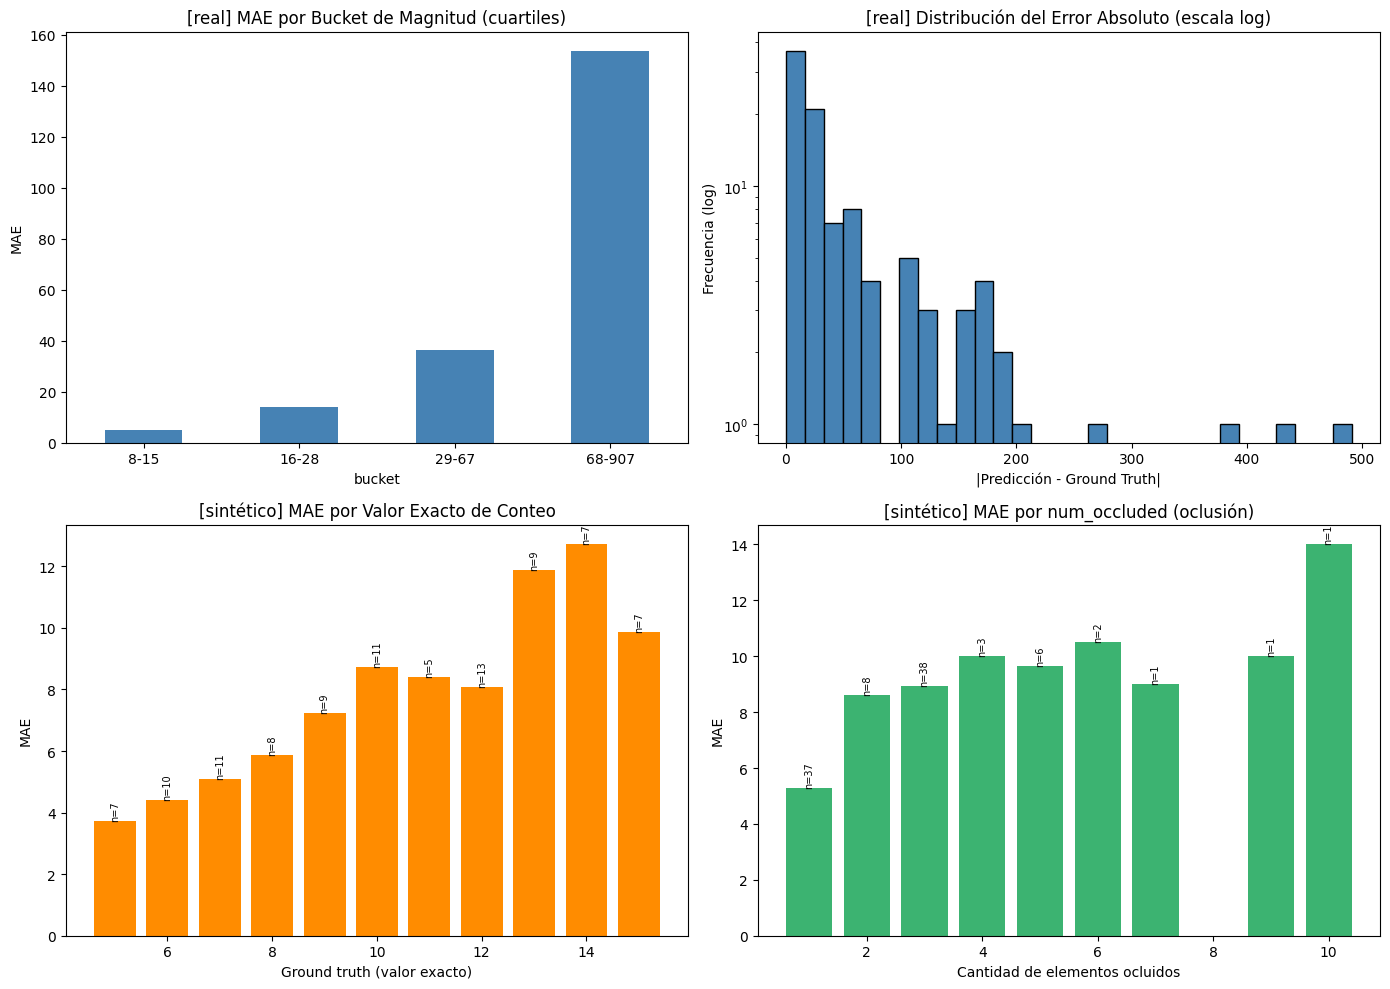


--- DIAGNÓSTICO: casos de mayor error en CAPTURe real ---
  GT= 501  Pred=10.0  Cat: polka dots  Raw: 'The image shows a black box with a black background. Inside the black box, there are 10 polka dots.

So, the total number of polka dots in the image is 10.'
  GT= 437  Pred=10.0  Cat: oranges  Raw: 'In the image, there are 10 oranges visible. The pattern of oranges continues behind the black box, so there are 10 more oranges in the black box.'
  GT= 381  Pred= 1.0  Cat: windows  Raw: 'To count the exact number of windows in the image, we need to carefully observe the pattern of windows behind the black box. The black box is a rectangular area that seems to separate the two rows of windows. 

Let's break down the pattern:

1. The first row has 10 windows.
2. The'
  GT= 270  Pred= 1.0  Cat: polka dots  Raw: 'The image shows a shirt with a polka dot pattern. To count the exact number of polka dots, we need to carefully observe the pattern and count the dots that are visible in the image

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. [real] MAE por bucket de magnitud
if len(validos_real):
    resumen_bucket_real = validos_real.groupby("bucket")["error_abs"].mean().reindex(
        [f"{lo}-{hi}" for lo, hi in CUARTILES_REAL]
    )
    resumen_bucket_real.plot(kind="bar", ax=axes[0, 0], color="steelblue")
    axes[0, 0].set_title("[real] MAE por Bucket de Magnitud (cuartiles)")
    axes[0, 0].set_ylabel("MAE")
    axes[0, 0].tick_params(axis="x", rotation=0)

# 2. [real] distribución de error (escala log en Y por el rango tan amplio)
if len(validos_real):
    axes[0, 1].hist(validos_real["error_abs"], bins=30, color="steelblue", edgecolor="black")
    axes[0, 1].set_yscale("log")
    axes[0, 1].set_title("[real] Distribución del Error Absoluto (escala log)")
    axes[0, 1].set_xlabel("|Predicción - Ground Truth|")
    axes[0, 1].set_ylabel("Frecuencia (log)")

# 3. [sintético] MAE por valor exacto, con n anotado
if len(validos_sint):
    barras = axes[1, 0].bar(resumen_valor_sint.index, resumen_valor_sint["mae"], color="darkorange")
    for gt, fila in resumen_valor_sint.iterrows():
        axes[1, 0].text(gt, fila["mae"], f"n={int(fila['n'])}", ha="center", va="bottom", fontsize=7, rotation=90)
    axes[1, 0].set_title("[sintético] MAE por Valor Exacto de Conteo")
    axes[1, 0].set_xlabel("Ground truth (valor exacto)")
    axes[1, 0].set_ylabel("MAE")

# 4. [sintético] MAE por num_occluded -- la variable de oclusion controlada
if len(validos_sint):
    barras2 = axes[1, 1].bar(resumen_occ.index, resumen_occ["mae"], color="mediumseagreen")
    for occ, fila in resumen_occ.iterrows():
        axes[1, 1].text(occ, fila["mae"], f"n={int(fila['n'])}", ha="center", va="bottom", fontsize=7, rotation=90)
    axes[1, 1].set_title("[sintético] MAE por num_occluded (oclusión)")
    axes[1, 1].set_xlabel("Cantidad de elementos ocluidos")
    axes[1, 1].set_ylabel("MAE")

plt.tight_layout()
plt.savefig("/content/graficos_resumen_capture.png", dpi=120)
plt.show()

# Diagnóstico de parseo: los 15 casos de mayor error en 'real'
print("\n--- DIAGNÓSTICO: casos de mayor error en CAPTURe real ---")
peores = validos_real.nlargest(15, "error_abs")[["categoria", "ground_truth", "prediccion", "respuesta_cruda"]]
for _, row in peores.iterrows():
    print(f"  GT={row['ground_truth']:>4}  Pred={row['prediccion']:>4}  Cat: {row['categoria']}  Raw: '{row['respuesta_cruda']}'")

## 10. Guardar resultados en `.txt` y `.csv`


In [12]:
import datetime

with open(OUTPUT_TXT_PATH, "w", encoding="utf-8") as f:
    f.write(f"BENCHMARK: {BENCHMARK_NAME}\n")
    f.write(f"MODELO: {MODEL_ID} (revision={MODEL_REVISION})\n")
    f.write(f"FECHA: {datetime.datetime.now().isoformat()}\n")
    f.write(f"MUESTRA_REAL: {n_real}/{len(real_metadata_df)}\n")
    f.write(f"MUESTRA_SINTETICA: {n_sint}/{len(synthetic_metadata_df)}\n")
    f.write(f"SEMILLA: {RANDOM_SEED}\n")
    f.write("-" * 50 + "\n")
    f.write(f"VRAM_PICO_MB: {vram_peak_mb:.2f}\n")
    f.write(f"RAM_PICO_MB: {ram_peak_mb:.2f}\n")
    f.write("-" * 50 + "\n")

    for nombre_subset, validos in [("real", validos_real), ("sintetico", validos_sint)]:
        sub = df[df["subset"] == nombre_subset]
        n_total = len(sub)
        if n_total == 0:
            continue
        n_timeouts = int(sub["timeout"].sum())
        n_parse_fail = int(sub["parse_fail"].sum())
        tiempos = sub[~sub["timeout"]]
        f.write(f"[{nombre_subset.upper()}]\n")
        f.write(f"  N: {n_total}\n")
        f.write(f"  TIMEOUT_RATE: {n_timeouts/n_total:.4f}\n")
        f.write(f"  PARSE_FAIL_RATE: {n_parse_fail/n_total:.4f}\n")
        f.write(f"  ACCURACY_EXACTA: {validos['acierto_exacto'].mean():.4f}\n")
        f.write(f"  MAE: {validos['error_abs'].mean():.4f}\n")
        f.write(f"  VARIANZA_ERROR: {validos['error_abs'].var():.4f}\n")
        f.write(f"  TIEMPO_MEDIO_SEG: {tiempos['tiempo_seg'].mean():.4f}\n")
        f.write("-" * 50 + "\n")

    if len(validos_real):
        f.write("DESGLOSE_REAL_POR_BUCKET_MAGNITUD\n")
        for b, grupo in validos_real.groupby("bucket"):
            f.write(f"  {b}: n={len(grupo)} accuracy={grupo['acierto_exacto'].mean():.4f} "
                    f"mae={grupo['error_abs'].mean():.4f}\n")
        f.write("-" * 50 + "\n")

    if len(validos_sint):
        f.write("DESGLOSE_SINTETICO_POR_VALOR_EXACTO\n")
        for gt, fila in resumen_valor_sint.iterrows():
            f.write(f"  GT={int(gt)}: n={int(fila['n'])} accuracy={fila['accuracy']:.4f} mae={fila['mae']:.4f}\n")
        f.write("-" * 50 + "\n")
        f.write("DESGLOSE_SINTETICO_POR_NUM_OCCLUDED\n")
        for occ, fila in resumen_occ.iterrows():
            f.write(f"  num_occluded={int(occ)}: n={int(fila['n'])} accuracy={fila['accuracy']:.4f} mae={fila['mae']:.4f}\n")
        f.write("-" * 50 + "\n")

    f.write("DETALLE_POR_PREGUNTA (subset | categoria | num_occluded | ground_truth | prediccion | parse_fail | timeout | error_abs | tiempo_seg)\n")
    for _, row in df.iterrows():
        f.write(f"  {row['subset']} | {row['categoria']} | {row['num_occluded']} | {row['ground_truth']} | "
                f"{row['prediccion']} | {row['parse_fail']} | {row['timeout']} | {row['error_abs']} | {row['tiempo_seg']:.3f}\n")

print(f"Resultados guardados en: {OUTPUT_TXT_PATH}")

df.to_csv(OUTPUT_CSV_PATH, index=False)
print(f"Detalle completo guardado como CSV en: {OUTPUT_CSV_PATH}")

try:
    from google.colab import files
    files.download(OUTPUT_TXT_PATH)
    files.download(OUTPUT_CSV_PATH)
except ImportError:
    print("No se detectó entorno Colab -- descarga los archivos manualmente desde el panel de archivos.")


Resultados guardados en: /content/resultados_CAPTURe_InternVL2-1B.txt
Detalle completo guardado como CSV en: /content/detalle_CAPTURe_InternVL2-1B.csv


/tmp/ipykernel_2209/1492659093.py:35: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for b, grupo in validos_real.groupby("bucket"):


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>